# 04 · Train and validate

Same idea as the organisers' notebook 01 (video features → ridge regression → predicted EEG →
compare with the real EEG), with the improvements we validated one by one.

**EEG preprocessing** (`mindreading/preprocess.py`)
1. 500 → 100 measurements per second (anti-alias filter, like the organisers).
2. **Channel whitening**: decorrelate the 17 electrodes using each file's own covariance (shrunk
   30% towards identity). The electrodes share a lot of noise; this removes it. It was the
   biggest single gain. It is unsupervised, so it is allowed on test files too.
3. z-score each file with its own statistics (the test files are scaled differently from the
   training files).
4. Keep 0–1 s after video onset (later windows only added noise).

**Model** (`mindreading/ensemble.py`): for each subject, three encoders whose scores are added:
- **subject**: trained on that subject's own training recordings
- **pooled**: trained on all 6 subjects' training recordings
- **ga**: trained on the *grand average* EEG over subjects for each video (much cleaner target)

Each encoder: video features → ridge regression → predicted EEG, with a **separate
regularisation strength for every electrode × time point**, so unpredictable points shrink to
zero. A recording is compared with every candidate video by correlating the real EEG with the
EEG predicted for that video.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repo root, so `mindreading` imports work
import numpy as np
import matplotlib.pyplot as plt
from mindreading.config import DATA_DIR, RESULTS_DIR, WEIGHTS_DIR, SUBMISSION_DIR
print('data folder:', DATA_DIR)

data folder: C:\Users\canbe\Desktop\eeg-mind-reading-challenge\eeg-mind-reading-challenge


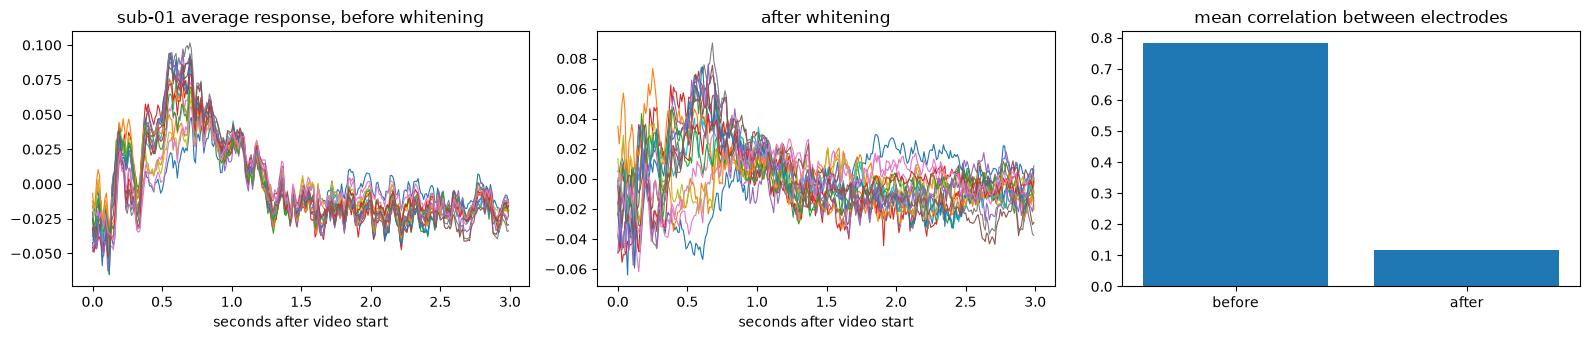

In [2]:
from mindreading.data import load_train
from mindreading.preprocess import downsample, normalise, whiten_channels
ids, raw = load_train(1)
x0 = normalise(downsample(raw))
x1 = normalise(whiten_channels(downsample(raw), 0.3))
t = np.arange(x0.shape[-1]) / 100
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
ax[0].plot(t, x0.mean(0).T, lw=0.8); ax[0].set_title('sub-01 average response, before whitening')
ax[1].plot(t, x1.mean(0).T, lw=0.8); ax[1].set_title('after whitening')
c0 = np.corrcoef(x0.transpose(1, 0, 2).reshape(17, -1)); c1 = np.corrcoef(x1.transpose(1, 0, 2).reshape(17, -1))
ax[2].bar(['before', 'after'], [c0[np.triu_indices(17, 1)].mean(), c1[np.triu_indices(17, 1)].mean()])
ax[2].set_title('mean correlation between electrodes')
for a in ax[:2]: a.set_xlabel('seconds after video start')
plt.tight_layout(); plt.show()

### How we got here
Every step was chosen on held-out *training* videos (never on test data). Full tables:
`results/experiment_log.md`.

In [3]:
from IPython.display import Markdown, display
display(Markdown((RESULTS_DIR / 'experiment_log.md').read_text(encoding='utf-8')))

# Experiment log

Every change was judged on **held-out training videos**: 15% of the 1,000 training videos are hidden, the model is trained on the rest, and each hidden recording is ranked against the ~150 hidden videos (chance: top-1 0.7%, top-5 3.3%). From round 3 on, results are averaged over 3 different random hidden sets to reduce noise. The sub-01…04 **test sets** (102 candidates, chance 1.0% / 4.9%) were used only to report milestone scores, never to choose settings.

Scripts: `scripts/search_settings.py` (round 0), `scripts/exp_eeg.py`, `scripts/exp_combo.py`.

## Round 0: base model (CLIP-B/32 card → ridge → predicted EEG, per-subject)
| setting | top-1 | top-5 |
|---|---|---|
| window 0–1 s (chosen) | 2.7% | 9.5% |
| window 0–0.6 / 0–2 / 0–3 s | | 8.6 / 8.1 / 6.8% |
| per-recording normalisation | | 7.8% |
| decoder direction (EEG → card) | | ~4.9% (chance) |

## Round 1: EEG preprocessing (CLIP-B/32, per-subject encoder)
| change | top-1 | top-5 |
|---|---|---|
| baseline | 2.7% | 9.5% |
| band-pass 0.1–30 Hz | 3.0% | 9.3% |
| low-pass 15 Hz | 2.7% | 10.0% |
| low-pass 8 Hz | 2.1% | 10.9% |
| **common average reference (CAR)** | 3.0% | **12.5%** |
| window 0.05–0.8 s | 2.7% | 9.5% |
| window 0–1.3 s | 2.4% | 9.4% |
| + model on all 6 subjects ("pooled") | 3.4% | 10.3% |
| + model on the grand-average EEG ("GA") | 3.1% | 9.9% |
| reliability-weighted correlation | 2.5% | 8.8% |

## Round 2: combining (CLIP-B/32)
| change | top-1 | top-5 |
|---|---|---|
| CAR | 3.0% | 12.5% |
| CAR + low-pass 12 Hz | 3.7% | 12.9% |
| CAR + band 0.5–8 Hz | 3.0% | 13.0% |
| CAR + subject + pooled | 3.8% | 12.8% |
| **CAR + subject + pooled + GA ensemble** | 3.8% | **13.7%** |
| ensemble + extra filtering | | 12.3–13.6% (no gain) |

## Round 3: sound (3 hidden sets averaged; encoder now only centres features so block weights work)
| features | top-1 | top-5 |
|---|---|---|
| CLIP-B/32 | 3.6% | 12.4% |
| audio alone (AST layer 4) | 1.6% | 8.0% |
| **CLIP + AST layer 4 (weight 0.5)** | 3.8% | **13.8%** |
| CLIP + AST layer 4 (weight 1.0) | 2.8% | 12.7% |

## Round 4: channel whitening (multivariate noise normalisation)
| change | top-1 | top-5 |
|---|---|---|
| CAR (reference) | 3.8% | 13.8% |
| CAR + whitening | 2.7–3.2% | 12.1–13.3% |
| whitening only, shrink 0.01 / 0.05 / 0.1 | | 13.9 / 15.0 / 15.3% |
| **whitening only, shrink 0.2–0.4** | 4.1–4.2% | **16.0–16.3%** |

## Round 5: more stimulus features (whitening 0.3, subject + pooled + GA)
| features | top-1 | top-5 |
|---|---|---|
| CLIP + AST4 | 4.3% | 16.2% |
| low-level time courses alone (brightness, contrast, motion, cuts, loudness, onsets) | 2.7% | 9.9% |
| **+ low-level (weight 0.6)** | 4.6% | **17.7%** |
| **+ separate ridge strength per EEG feature** | 5.1% | **19.3%** |
| VideoMAE alone | 4.8% | 16.0% |
| **+ VideoMAE layers 4/8/12 (weight 0.6)** | 5.2% | **20.9%** |
| VideoMAE layer 4 / 8 / 12 only, or other PCA sizes | | 18.7–20.8% (no gain) |

## Round 6: a bigger image model (CLIP ViT-L/14, 16 frames, final + layers 6/12/18/24)
| features | top-1 | top-5 |
|---|---|---|
| current best (CLIP-B/32 + AST4 + low-level + VideoMAE) | 5.2% | 20.9% |
| CLIP-L/14 embedding alone | 3.5% | 14.8% |
| CLIP-L/14 intermediate layers alone | 5.0% | 17.0% |
| swap CLIP-B/32 for CLIP-L/14 | 5.5% | 20.0% |
| best + CLIP-L/14 (weight 0.4 / 0.8, embedding or layers) | 5.1–5.5% | 20.3–20.7% |

No gain: a bigger image model does not explain the EEG better. Motion (VideoMAE), low-level timing and sound add more than a stronger object recogniser. Not used.

## Milestone scores on the sub-01…04 test sets (102 candidates)
| model | top-1 | top-5 | median rank |
|---|---|---|---|
| organisers' baseline (AlexNet) | ~4% | 11.7% | |
| base: CLIP + per-subject ridge | 5.1% | 23.3% | 18.3 |
| + CAR, 3-model ensemble, audio | 7.1% | 25.7% | 15.3 |
| + whitening, low-level features | 14.0% | 37.0% | 10.1 |
| + per-feature ridge strength | 13.7% | 36.5% | 9.1 |
| **+ VideoMAE** | **15.2%** | **41.7%** | **8.3** |


### Validation on held-out training videos (3 random hidden sets, ~150 candidates, chance 3.3% top-5)
Takes a few minutes. Shows each ensemble member on its own and the full ensemble.

In [4]:
from mindreading.ensemble import EnsembleConfig, EnsembleModel, validate, dev_test
cfg = EnsembleConfig()
model = EnsembleModel(cfg)
val = validate(cfg, model=model)
for k, v in val.items():
    print(f"{k:9s} top1 {v['top1']:.3f}  top5 {v['top5']:.3f}  median rank {v['median_rank']:.1f}")

subject   top1 0.063  top5 0.205  median rank 21.5
pooled    top1 0.040  top5 0.164  median rank 27.7
ga        top1 0.042  top5 0.171  median rank 28.4
ensemble  top1 0.061  top5 0.209  median rank 20.7


### Score on the sub-01…04 test sets (102 candidates, chance 1.0% / 4.9%)
Organisers' AlexNet baseline: about **4% top-1, 11.7% top-5**.

In [5]:
from mindreading.pipeline import summarise
res = dev_test(cfg, model=model)
for s, r in res.items():
    e = r['ensemble']
    print(f"sub-0{s}: top1 {e['top1']:.3f}  top5 {e['top5']:.3f}  median rank {e['median_rank']:.0f}")
mean = summarise(res)
for k, v in mean.items():
    print(f"mean {k:9s} top1 {v['top1']:.3f}  top5 {v['top5']:.3f}")
RESULTS_DIR.mkdir(exist_ok=True)
(RESULTS_DIR / 'dev_test_scores.json').write_text(json.dumps(
    {'config': cfg.__dict__, 'validation': val, 'per_subject': res, 'mean': mean}, indent=2, default=str))

sub-01: top1 0.196  top5 0.500  median rank 6
sub-02: top1 0.167  top5 0.422  median rank 7
sub-03: top1 0.147  top5 0.510  median rank 5
sub-04: top1 0.157  top5 0.412  median rank 8
mean subject   top1 0.172  top5 0.461
mean pooled    top1 0.110  top5 0.338
mean ga        top1 0.125  top5 0.343
mean ensemble  top1 0.167  top5 0.461


3513

### Sanity check: shuffled labels must score at chance
Train again, but pair every training recording with a *random* video. If the score stays above
chance, information is leaking from somewhere.

In [6]:
from dataclasses import replace
shuf = summarise(dev_test(replace(cfg, shuffle_labels=True), model=EnsembleModel(replace(cfg, shuffle_labels=True), model.feats)))
print(f"shuffled: top1 {shuf['ensemble']['top1']:.3f}  top5 {shuf['ensemble']['top5']:.3f}   (chance 0.010 / 0.049)")

shuffled: top1 0.007  top5 0.027   (chance 0.010 / 0.049)
